<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/string_theory/string_ch08_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*String Theory* — `string_ch08_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# String Theory Ch 8 — Figure Notebook
**Compactification and T-Duality**

#### matplotlib mathtext 미지원 → 대체 목록 ──────────────────────────────
* \implies          → \Rightarrow
* \iff              → \Leftrightarrow
* \xleftrightarrow  → \overset{T}{\longleftrightarrow}
* \stackrel         → \overset
* \begin{pmatrix}   → 성분 나열 (\gamma_{00}=... 형태)
* \alpha\'          → \alpha^{\prime}
* \alpha^{\prime}^n → {\alpha^{\prime}}^{n}
* \text{X}          → \mathrm{X}
* \mathbb{R}        → \mathbf{R} 또는 평문
* axhline(transform=transAxes) → ax.plot([x0,x1],[y,y], transform=transAxes)

In [1]:
FIG_DIR = 'figures/ch08'

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os

BG='#1e1e2e';FG='#cdd6f4';EDGE='#45475a'
SKYB='#89c4f4';YELL='#f9c74f';GREEN='#90ee90'
RED='#e07070';PURP='#c792ea';ORAN='#e8a838';TEAL='#2ec4b6'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,
    'text.color':FG,'axes.labelcolor':FG,
    'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.25,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':SKYB,'legend.framealpha':0.3,
    'legend.edgecolor':EDGE,'lines.linewidth':2.2,
    'axes.linewidth':1.2,'figure.dpi':110,
})
os.makedirs(FIG_DIR, exist_ok=True)

def save(name, fig):
    fig.savefig(f'{FIG_DIR}/{name}', dpi=150, bbox_inches='tight', facecolor=BG)
    plt.show(); print(f'Saved: {FIG_DIR}/{name}')

print('Setup complete.')


Setup complete.


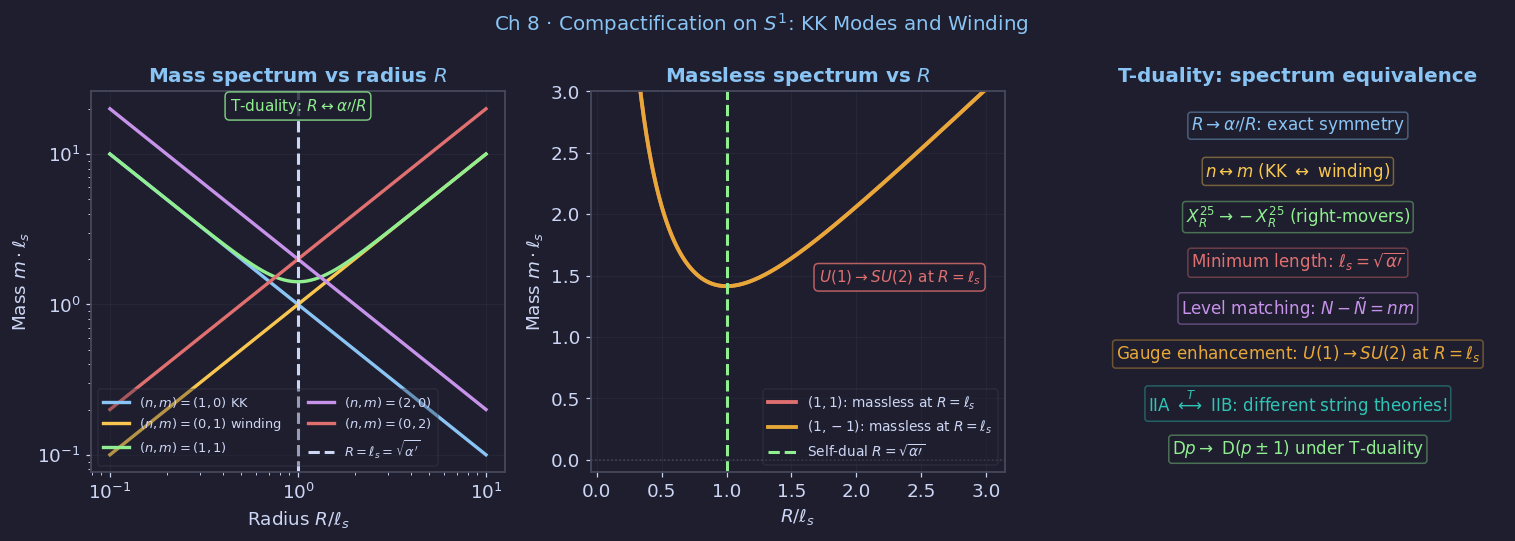

Saved: figures/ch08/fig01_kk_winding_spectrum.png


In [2]:

# ── fig01: KK modes and winding — mass spectrum ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('Ch 8 · Compactification on $S^1$: KK Modes and Winding',
             color=SKYB, fontsize=13)

alpha_prime = 1.0

# Left: mass spectrum vs R for (n,m) modes
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'Mass spectrum vs radius $R$', color=SKYB)
R_vals = np.logspace(-1, 1, 300)

for (n, m, col, lbl) in [
    (1, 0, SKYB,  r'$(n,m)=(1,0)$ KK'),
    (0, 1, YELL,  r'$(n,m)=(0,1)$ winding'),
    (1, 1, GREEN, r'$(n,m)=(1,1)$'),
    (2, 0, PURP,  r'$(n,m)=(2,0)$'),
    (0, 2, RED,   r'$(n,m)=(0,2)$'),
]:
    m2 = (n/R_vals)**2 + (m*R_vals/alpha_prime)**2
    ax.loglog(R_vals, np.sqrt(m2), color=col, lw=2.2, label=lbl)

ax.axvline(np.sqrt(alpha_prime), color=FG, lw=2, ls='--',
           label=r'$R=\ell_s=\sqrt{\alpha^{\prime}}$')
ax.set_xlabel(r'Radius $R/\ell_s$')
ax.set_ylabel(r'Mass $m\cdot\ell_s$')
ax.legend(fontsize=8.5, ncol=2); ax.grid(True, alpha=0.2)
ax.text(0.5, 0.95, r'T-duality: $R\leftrightarrow\alpha\prime/R$',
        transform=ax.transAxes, ha='center', fontsize=10, color=GREEN,
        bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.8))

# Middle: self-dual radius and gauge enhancement
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'Massless spectrum vs $R$', color=SKYB)
R_lin = np.linspace(0.1, 3.0, 300)
# KK and winding masses that go to zero at R_sd
for (n, m, col, lbl) in [(1,1,RED,r'$(1,1)$: massless at $R=\ell_s$'),
                          (1,-1,ORAN,r'$(1,-1)$: massless at $R=\ell_s$')]:
    pL = n/R_lin + m*R_lin/alpha_prime
    pR = n/R_lin - m*R_lin/alpha_prime
    # mass^2 = pL^2/2 + pR^2/2 + N + Ntilde - 2 (for N=Ntilde=1)
    m2 = pL**2/2 + pR**2/2 - 2 + 2  # N=Ntilde=1 contribution = 2, -2 cancels
    m2_actual = (pL**2 + pR**2)/2   # mass^2 at N=Ntilde=1
    ax2.plot(R_lin, np.sqrt(np.abs(m2_actual)), color=col, lw=2.5, label=lbl)

ax2.axvline(np.sqrt(alpha_prime), color=GREEN, lw=2, ls='--',
            label=r'Self-dual $R=\sqrt{\alpha\prime}$')
ax2.axhline(0, color=EDGE, lw=1, ls=':')
ax2.set_xlabel(r'$R/\ell_s$')
ax2.set_ylabel(r'Mass $m\cdot\ell_s$')
ax2.set_ylim(-0.1, 3); ax2.legend(fontsize=9); ax2.grid(True, alpha=0.2)
ax2.text(0.55, 0.50,
         r'$U(1)\to SU(2)$ at $R=\ell_s$',
         transform=ax2.transAxes, fontsize=10, color=RED,
         bbox=dict(boxstyle='round', fc=BG, ec=RED, alpha=0.8))

# Right: T-duality diagram
ax3 = axes[2]; ax3.set_facecolor(BG); ax3.axis('off')
ax3.set_title('T-duality: spectrum equivalence', color=SKYB)
items = [
    (0.5, 0.91, r'$R\to\alpha\prime/R$: exact symmetry', SKYB),
    (0.5, 0.79, r'$n\leftrightarrow m$ (KK $\leftrightarrow$ winding)', YELL),
    (0.5, 0.67, r'$X^{25}_R\to-X^{25}_R$ (right-movers)', GREEN),
    (0.5, 0.55, r'Minimum length: $\ell_s=\sqrt{\alpha\prime}$', RED),
    (0.5, 0.43, r'Level matching: $N-\tilde N=nm$', PURP),
    (0.5, 0.31, r'Gauge enhancement: $U(1)\to SU(2)$ at $R=\ell_s$', ORAN),
    (0.5, 0.18, r'IIA $\overset{T}{\longleftrightarrow}$ IIB: different string theories!', TEAL),
    (0.5, 0.06, r'D$p\to$ D$(p\pm 1)$ under T-duality', GREEN),
]
for x_,y_,txt,col in items:
    ax3.text(x_,y_,txt,ha='center',va='center',fontsize=11,color=col,
             transform=ax3.transAxes,
             bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.4))

plt.tight_layout()
save('fig01_kk_winding_spectrum.png', fig)


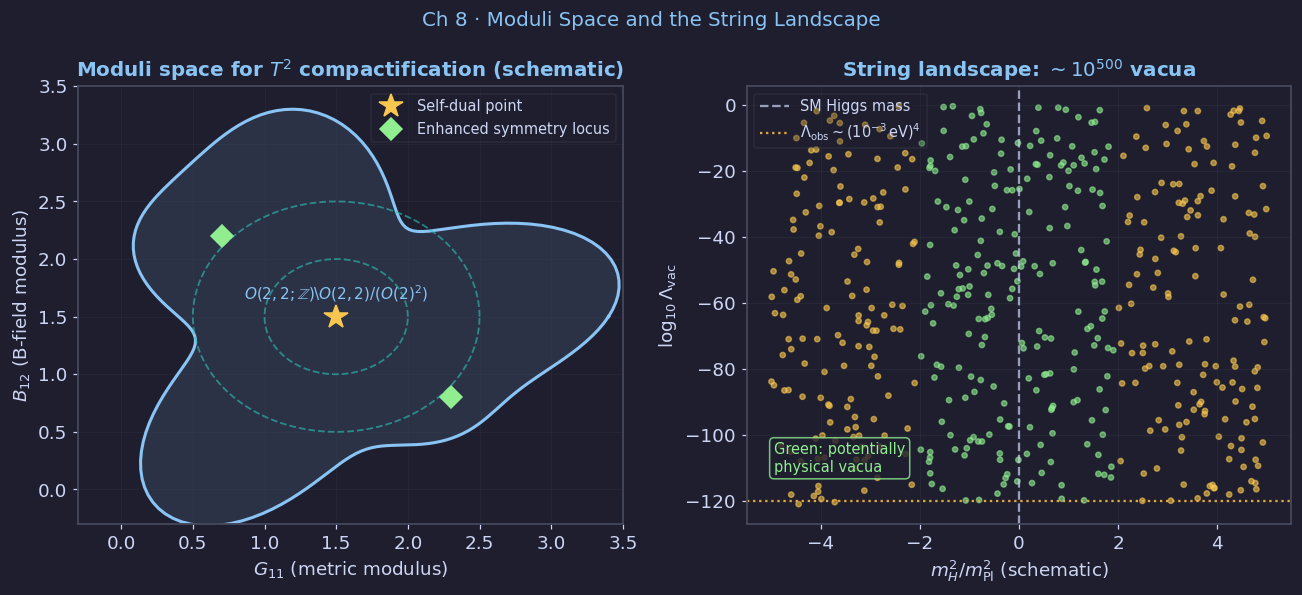

Saved: figures/ch08/fig02_moduli_landscape.png


In [3]:

# ── fig02: Moduli space of toroidal compactification ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle(r'Ch 8 · Moduli Space and the String Landscape',
             color=SKYB, fontsize=13)

# Left: moduli space schematic for T^2 (2-torus)
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'Moduli space for $T^2$ compactification (schematic)', color=SKYB)
ax.set_xlim(-0.3, 3.5); ax.set_ylim(-0.3, 3.5)

# Draw a region representing the moduli space
theta_ms = np.linspace(0, 2*np.pi, 200)
# Schematic Narain moduli space (simplified projection)
r_ms = 1.5 + 0.4*np.cos(3*theta_ms) + 0.2*np.sin(5*theta_ms)
x_ms = 1.5 + r_ms*np.cos(theta_ms)
y_ms = 1.5 + r_ms*np.sin(theta_ms)
ax.fill(x_ms, y_ms, color=SKYB, alpha=0.12)
ax.plot(x_ms, y_ms, color=SKYB, lw=2)
ax.text(1.5, 1.7, r'$O(2,2;\mathbb{Z})\backslash O(2,2)/(O(2)^2)$',
        ha='center', va='center', fontsize=10, color=SKYB)

# Mark special points
ax.plot([1.5],[1.5],'*', color=YELL, ms=16, zorder=8,
        label='Self-dual point')
ax.plot([0.7],[2.2],'D', color=GREEN, ms=10, zorder=8,
        label='Enhanced symmetry locus')
ax.plot([2.3],[0.8],'D', color=GREEN, ms=10, zorder=8)

# T-duality orbits
for r_orb in [0.5, 1.0]:
    xo = 1.5 + r_orb*np.cos(theta_ms)
    yo = 1.5 + r_orb*np.sin(theta_ms)
    ax.plot(xo, yo, color=TEAL, lw=1.2, ls='--', alpha=0.6)

ax.set_xlabel(r'$G_{11}$ (metric modulus)')
ax.set_ylabel(r'$B_{12}$ (B-field modulus)')
ax.legend(fontsize=9.5); ax.grid(True, alpha=0.15)

# Right: landscape
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'String landscape: $\sim 10^{500}$ vacua', color=SKYB)
rng = np.random.default_rng(42)

# Scatter plot representing landscape vacua
N_vac = 500
Lambda_vac = rng.exponential(1, N_vac) * 10**rng.uniform(-120, 0, N_vac)
m_higgs = rng.uniform(-5, 5, N_vac)
colors_vac = [GREEN if (l > 0 and abs(m) < 2) else (YELL if l > 0 else RED)
              for l, m in zip(Lambda_vac, m_higgs)]

ax2.scatter(m_higgs, np.log10(np.abs(Lambda_vac)+1e-130),
            c=colors_vac, s=12, alpha=0.6)
ax2.axvline(0, color=FG, lw=1.5, ls='--', alpha=0.7, label='SM Higgs mass')
ax2.axhline(-120, color=ORAN, lw=1.5, ls=':', label=r'$\Lambda_{\rm obs}\sim(10^{-3}\,{\rm eV})^4$')

ax2.set_xlabel(r'$m_H^2/m_{\rm Pl}^2$ (schematic)')
ax2.set_ylabel(r'$\log_{10}\Lambda_{\rm vac}$')
ax2.legend(fontsize=9.5); ax2.grid(True, alpha=0.2)
ax2.text(0.05, 0.12,
         'Green: potentially\nphysical vacua',
         transform=ax2.transAxes, fontsize=9.5, color=GREEN,
         bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.8))

plt.tight_layout()
save('fig02_moduli_landscape.png', fig)


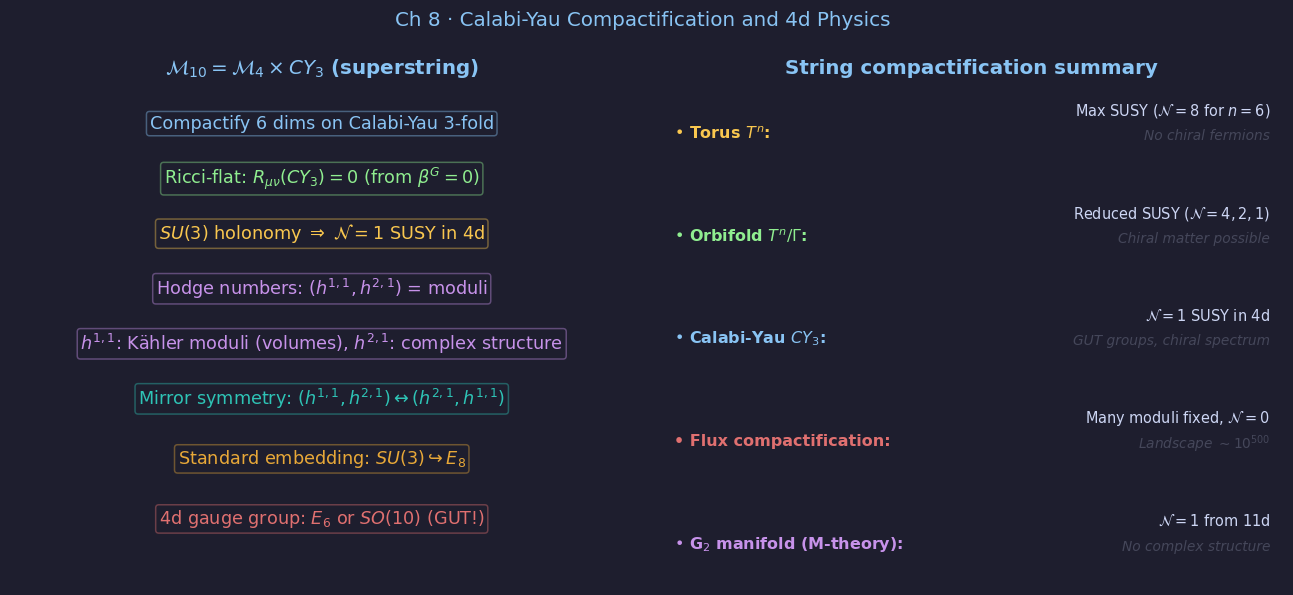

Saved: figures/ch08/fig03_calabi_yau.png


In [4]:

# ── fig03: Calabi-Yau compactification and 4d physics ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
fig.suptitle('Ch 8 · Calabi-Yau Compactification and 4d Physics',
             color=SKYB, fontsize=13)

ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r'$\mathcal{M}_{10}=\mathcal{M}_4\times CY_3$ (superstring)', color=SKYB)
items = [
    (0.5, 0.92, r'Compactify 6 dims on Calabi-Yau 3-fold', SKYB),
    (0.5, 0.81, r'Ricci-flat: $R_{\mu\nu}(CY_3)=0$ (from $\beta^G=0$)', GREEN),
    (0.5, 0.70, r'$SU(3)$ holonomy $\Rightarrow$ $\mathcal{N}=1$ SUSY in 4d', YELL),
    (0.5, 0.59, r'Hodge numbers: $(h^{1,1},h^{2,1})$ = moduli', PURP),
    (0.5, 0.48, r'$h^{1,1}$: Kähler moduli (volumes), $h^{2,1}$: complex structure', PURP),
    (0.5, 0.37, r'Mirror symmetry: $(h^{1,1},h^{2,1})\leftrightarrow(h^{2,1},h^{1,1})$', TEAL),
    (0.5, 0.25, r'Standard embedding: $SU(3)\hookrightarrow E_8$', ORAN),
    (0.5, 0.13, r'4d gauge group: $E_6$ or $SO(10)$ (GUT!)', RED),
]
for x_,y_,txt,col in items:
    ax.text(x_,y_,txt,ha='center',va='center',fontsize=11.5,color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.18',fc=BG,ec=col,alpha=0.4))

# Right: comparison of compactification schemes
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title('String compactification summary', color=SKYB)

schemes = [
    (r'Torus $T^n$',
     r'Max SUSY ($\mathcal{N}=8$ for $n=6$)',
     'No chiral fermions', YELL),
    (r'Orbifold $T^n/\Gamma$',
     r'Reduced SUSY ($\mathcal{N}=4,2,1$)',
     'Chiral matter possible', GREEN),
    (r'Calabi-Yau $CY_3$',
     r'$\mathcal{N}=1$ SUSY in 4d',
     r'GUT groups, chiral spectrum', SKYB),
    ('Flux compactification',
     r'Many moduli fixed, $\mathcal{N}=0$',
     r'Landscape $\sim 10^{500}$', RED),
    (r'G$_2$ manifold (M-theory)',
     r'$\mathcal{N}=1$ from 11d',
     r'No complex structure', PURP),
]
ys3 = np.linspace(0.90, 0.08, len(schemes))
for (name, prop1, prop2, col), y_ in zip(schemes, ys3):
    ax2.text(0.02, y_, f'• {name}:', color=col, fontsize=10.5,
             fontweight='bold', va='center', transform=ax2.transAxes)
    ax2.text(0.98, y_+0.045, prop1, color=FG, fontsize=9.5, ha='right',
             va='center', transform=ax2.transAxes)
    ax2.text(0.98, y_-0.005, prop2, color=EDGE, fontsize=9, ha='right',
             va='center', transform=ax2.transAxes, style='italic')

plt.tight_layout()
save('fig03_calabi_yau.png', fig)


In [5]:
# ── Download all figures as a zip ────────────────────────────────────────
import shutil

shutil.make_archive('ch08_figures', 'zip', 'figures/ch08')

try:
    from google.colab import files
    files.download('ch08_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — figures saved to figures/ch08/')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
